# Bay Area Food Access and Health

#### This notebook combines the main tract-level data preparation and early analysis for Alameda, Contra Costa, and San Francisco counties. It uses 2023 ACS five-year estimates, CDC PLACES 2025 health estimates, the saved food-place file, and the selected tract boundaries. The notebook retrieves ACS data from the Census API; no API key is needed for these county-level requests. The analysis is exploratory. Counts within 0.5 and 5 straight-line miles are distance proxies, not walking or driving route times. Tract-level associations do not show that food access causes a health outcome.

## Import Libraries

In [1]:
import os
from pathlib import Path

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import numpy as np
import matplotlib as mpl
import shapely.wkt

from shapely.geometry import Point
from shapely import wkt
from dotenv import load_dotenv
from IPython.display import display
from matplotlib.lines import Line2D
from scipy.spatial import cKDTree

## Census Data Cleaning and Household Indicators

### Cleaning Census Data

#### Helper Functions

In [2]:
def clean_census_types(df,rename_map,float_cols=("median_age", "avg_hh_size"),id_widths=None):
    """Return cleaned copy and the available ACS column names"""
    
    df = df.copy().rename(columns=rename_map)
    if id_widths is None:
        id_widths = {"geoid": 11,"county": 3,"state": 2, "tract": 6}

    acs_cols = [name for code, name in rename_map.items() if code != "NAME" and name in df.columns]

    for col in acs_cols:
        dtype = "float64" if col in float_cols else "Int64"
        df[col] = pd.to_numeric(df[col], errors="coerce").astype(dtype)
    for col, width in id_widths.items():
        ids = (df[col].astype("string").str.strip().replace({"": pd.NA, "nan": pd.NA, "None": pd.NA}).str.replace(r"\.0$", "", regex=True))

        valid = ids.str.fullmatch(rf"\d{{1,{width}}}", na=False)
        invalid = ids.notna() & ~valid

        if invalid.any():
            raise ValueError(f"Invalid {col} values: {ids[invalid].head().tolist()}")

        df[col] = ids.str.zfill(width)

    return df, acs_cols


def clean_sentinels(df,acs_cols, sentinel_threshold=-1e8, topcode_col="median_hh_income",topcode_value=250001):
    """Return flagged original data & a copy with sentinels removed"""
    
    df = df.copy()
    acs_cols = list(acs_cols)

    vals = df[acs_cols].astype("float64")
    is_sent = vals < sentinel_threshold

    df["has_sentinel"] = is_sent.any(axis=1)

    if topcode_col is not None:
        df["income_topcoded"] = (df[topcode_col].eq(topcode_value).fillna(False))

    viz = df.copy()
    viz[acs_cols] = vals.mask(is_sent)

    return df, viz


def estimate_missing_vehicles(df, vehicle_weights=None,target_col="aggregate_vehicles",household_col="total_hh",flag_col="vehicles_estimated"):
    
    """Fill missing totals when all vehicle components are available"""
    df = df.copy()

    if vehicle_weights is None:
        vehicle_weights = {"hh_veh_1": 1,"hh_veh_2": 2,"hh_veh_3": 3,"hh_veh_4plus": 4}

    if not vehicle_weights:
        raise ValueError("vehicle_weights must not be empty.")

    columns = list(vehicle_weights)

    estimates = (df[columns].mul(pd.Series(vehicle_weights), axis="columns").sum(axis=1, min_count=len(columns)))

    gap = (df[target_col].isna() & estimates.notna() & df[household_col].gt(0)).fillna(False)

    if flag_col in df.columns:
        previous_flags = df[flag_col].fillna(False).astype(bool)
    else:
        previous_flags = pd.Series(False, index=df.index)

    # Allow fractional estimates if different weights
    df[target_col] = df[target_col].astype("float64")
    df.loc[gap, target_col] = estimates[gap]
    df[flag_col] = previous_flags | gap

    return df

def prep_geography(df, county_names, geometry_col="geometry", county_col="county", name_col="county_name", source_crs="EPSG:4326", target_crs="EPSG:3310"):
    """Accept WKT/geometry objects & preserve existing CRS"""
    
    df = df.copy()

    if not isinstance(df[geometry_col].dtype, gpd.array.GeometryDtype):
        df[geometry_col] = gpd.GeoSeries.from_wkt(df[geometry_col],index=df.index)

    gdf = gpd.GeoDataFrame(df, geometry=geometry_col)

    if gdf.crs is None:
        gdf = gdf.set_crs(source_crs)

    gdf = gdf.to_crs(target_crs)
    gdf[name_col] = gdf[county_col].map(county_names)

    return gdf

def pct(numerator, denominator):
    """Return percentages- missing/nonpositive denominators produce NaN."""
    return 100 * numerator / denominator.where(denominator > 0)

def add_indicators(df, indicators):
    """
    Add percentage columns without modifying the input.

    {"output": ("numerator_column", "denominator_column")}

    All listed components must be available to calculate
    """
    df = df.copy()

    for output, (numerator, denominator) in indicators.items():
        if isinstance(numerator, str):
            values = df[numerator]
        else:
            columns = list(numerator)

            if not columns:
                raise ValueError(f"No numerator columns supplied for {output}.")

            values = df[columns].sum(axis=1, min_count=len(columns))

        df[output] = pct(values, df[denominator])

    return df

def plot_choropleths(gdf, maps, ncols=2, figsize=None, cmap="viridis", scheme="quantiles", k=5):
    """Plot any number of mapped columns; return figure and axes."""
    
    if not maps:
        raise ValueError("maps must contain at least one column")
    if ncols < 1:
        raise ValueError("ncols must be at least 1")

    ncols = min(ncols, len(maps))
    nrows = (len(maps) + ncols - 1) // ncols

    if figsize is None:
        figsize = (7 * ncols, 6 * nrows)

    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)

    for ax, (column, title) in zip(axes.flat, maps.items()):
        options = {}
        if scheme is not None:
            options = {"scheme": scheme, "k": k}

        gdf.plot(column=column, cmap=cmap,legend=True, ax=ax,linewidth=0.1, edgecolor="white", missing_kwds={"color": "lightgray"}, **options)

        ax.set_title(title)
        ax.set_axis_off()

    for ax in list(axes.flat)[len(maps):]:
        ax.set_visible(False)

    return fig, axes

def plot_grouped_scatter(df, x, y, group_col, colors, size_col=None, size_scale=40, quantile=None, figsize=(8, 6.5)):
    """Plot grouped points w/optional bubble sizes & quantile lines."""
    
    if size_scale <= 0:
        raise ValueError("size_scale must be positive.")

    if quantile is not None and not 0 <= quantile <= 1:
        raise ValueError("quantile must be between 0 and 1.")

    required = list(dict.fromkeys(
        [x, y, group_col] + ([size_col] if size_col else [])
    ))
    plot_data = df.dropna(subset=required).copy()

    if size_col is not None:
        plot_data = plot_data.loc[plot_data[size_col] >= 0]

    groups = plot_data[group_col].unique()
    missing_colors = [name for name in groups if name not in colors]

    if missing_colors:
        raise ValueError(f"Missing colors for: {missing_colors}")

    fig, ax = plt.subplots(figsize=figsize)

    for name, group in plot_data.groupby(group_col, observed=True):
        sizes = 40 if size_col is None else group[size_col] / size_scale

        ax.scatter( group[x], group[y], s=sizes, alpha=0.5, color=colors[name], edgecolor="white", linewidth=0.3)

    # Use each full input column, matching the original percentile logic
    if quantile is not None:
        x_cutoff = df[x].quantile(quantile)
        y_cutoff = df[y].quantile(quantile)

        if pd.notna(x_cutoff):
            ax.axvline(x_cutoff, color="gray", ls="--", lw=0.8)
        if pd.notna(y_cutoff):
            ax.axhline(y_cutoff, color="gray", ls="--", lw=0.8)

    handles = [
        Line2D(
            [0], [0],
            marker="o",
            ls="",
            color=color,
            label=name,
            markersize=8,
            alpha=0.7,
        )
        for name, color in colors.items()
        if name in groups]

    ax.legend(handles=handles, frameon=False)
    ax.spines[["top", "right"]].set_visible(False)

    return fig, ax

### Converting Applicable Columns Into Int or Float Types, and Leaving IDs in String Formats

In [3]:
rename_map = {
    "NAME": "tract_name",
    "B03002_001E": "total_pop", "B03002_003E": "nh_white", "B03002_004E": "nh_black",
    "B03002_005E": "nh_aian", "B03002_006E": "nh_asian", "B03002_007E": "nh_nhpi",
    "B03002_008E": "nh_other_race", "B03002_009E": "nh_two_or_more", "B03002_012E": "hispanic_latino",
    "B01002_001E": "median_age", "B09001_001E": "pop_under_18",
    "B01001_020E": "male_65_66", "B01001_021E": "male_67_69", "B01001_022E": "male_70_74",
    "B01001_023E": "male_75_79", "B01001_024E": "male_80_84", "B01001_025E": "male_85_plus",
    "B01001_044E": "female_65_66", "B01001_045E": "female_67_69", "B01001_046E": "female_70_74",
    "B01001_047E": "female_75_79", "B01001_048E": "female_80_84", "B01001_049E": "female_85_plus",
    "B19013_001E": "median_hh_income", "B19113_001E": "median_family_income", "B19301_001E": "per_capita_income",
    "C17002_001E": "poverty_universe", "C17002_002E": "ratio_u050", "C17002_003E": "ratio_050_099",
    "C17002_004E": "ratio_100_124", "C17002_005E": "ratio_125_149", "C17002_006E": "ratio_150_184",
    "C17002_007E": "ratio_185_199",
    "B22003_002E": "hh_snap",
    "B08201_001E": "total_hh", "B08201_002E": "hh_veh_0", "B08201_003E": "hh_veh_1",
    "B08201_004E": "hh_veh_2", "B08201_005E": "hh_veh_3", "B08201_006E": "hh_veh_4plus",
    "B25046_001E": "aggregate_vehicles", "B25010_001E": "avg_hh_size",
    "B08301_001E": "total_workers", "B08301_010E": "workers_transit",
    "B08301_019E": "workers_walk", "B08301_021E": "workers_wfh",
    }

data_path = "data/selected_census_data"

selected_census_data = pd.read_csv(
    data_path,
    dtype={
        "geoid": "string",
        "county": "string",
        "state": "string",
        "tract": "string",
    })

selected_census_data, acs_cols = clean_census_types(selected_census_data,rename_map)

# check for NaNs
missing_counts = selected_census_data[acs_cols].isna().sum()
print(missing_counts[missing_counts > 0])

aggregate_vehicles    24
dtype: int64


In [4]:
display(selected_census_data.loc[selected_census_data["total_pop"].eq(0)])

,tract_name,total_pop,nh_white,nh_black,nh_aian,nh_asian,nh_nhpi,nh_other_race,nh_two_or_more,hispanic_latino,...,total_workers,workers_transit,workers_walk,workers_wfh,state,county,tract,geoid,countyfp,geometry
324,Census Tract 4443.03; Alameda County; California,0,0,0,0,0,0,0,0,0,...,0,0,0,0,06,001,444303,06001444303,1.0,MULTIPOLYGON (((-122.10179291503596 37.5177463...
378,Census Tract 9900; Alameda County; California,0,0,0,0,0,0,0,0,0,...,0,0,0,0,06,001,990000,06013990000,13.0,POLYGON ((-122.40910999965438 37.9206999999330...
620,Census Tract 9900; Contra Costa County; Califo...,0,0,0,0,0,0,0,0,0,...,0,0,0,0,06,013,990000,06013990000,13.0,POLYGON ((-122.40910999965438 37.9206999999330...
859,Census Tract 9804.01; San Francisco County; Ca...,0,0,0,0,0,0,0,0,0,...,0,0,0,0,06,075,980401,06075980401,75.0,MULTIPOLYGON (((-123.00055999994889 37.6951400...
863,Census Tract 9901; San Francisco County; Calif...,0,0,0,0,0,0,0,0,0,...,0,0,0,0,06,075,990100,<NA>,NaN,NaN
864,Census Tract 9902; San Francisco County; Calif...,0,0,0,0,0,0,0,0,0,...,0,0,0,0,06,075,990200,06075990200,75.0,MULTIPOLYGON (((-122.32785034320709 37.7810815...


### Keeping relevant tracts & columns

- 6 Census tracts with no population - AC: 444303, 990000, CC: 990000, SF: 980401, 990100, 990200
- Drop from analysis since our focus is on food deserts that directly affect people
- Columns 'county' & 'countyfp' are redundant from above join, so will drop 'countyfp'

In [5]:
new_df = (selected_census_data.loc[selected_census_data["total_pop"].gt(0)].drop(columns=["countyfp"], errors="ignore").copy())
new_df.head()

,tract_name,total_pop,nh_white,nh_black,nh_aian,nh_asian,nh_nhpi,nh_other_race,nh_two_or_more,hispanic_latino,...,avg_hh_size,total_workers,workers_transit,workers_walk,workers_wfh,state,county,tract,geoid,geometry
0,Census Tract 4001; Alameda County; California,3132,2051,156,0,544,0,25,142,214,...,2.34,1687,56,69,644,06,001,400100,06001400100,POLYGON ((-122.24692320219388 37.8853599659457...
1,Census Tract 4002; Alameda County; California,2203,1428,45,19,274,0,8,227,202,...,2.41,1158,174,21,577,06,001,400200,06001400200,POLYGON ((-122.25793619886238 37.8426109616014...
2,Census Tract 4003; Alameda County; California,5990,3486,518,22,475,0,0,918,571,...,2.06,3555,661,84,1354,06,001,400300,06001400300,POLYGON ((-122.26564419944195 37.8376409606255...
3,Census Tract 4004; Alameda County; California,4399,2711,337,0,517,0,29,296,509,...,2.41,2427,356,105,1104,06,001,400400,06001400400,POLYGON ((-122.26183919933446 37.8416279612341...
4,Census Tract 4005; Alameda County; California,3579,1646,757,3,263,7,34,233,636,...,2.12,1904,200,35,879,06,001,400500,06001400500,POLYGON ((-122.26952020129912 37.8485869612473...


### Inspecting data before sentinel code cleaning

In [6]:
new_df.info()

print("\nMissing values per column:")
print(new_df.isna().sum())

print("\nSummary before sentinel cleaning:")
display(new_df[["total_pop","median_hh_income","per_capita_income","aggregate_vehicles"]].describe())

<class 'pandas.core.frame.DataFrame'>
Index: 859 entries, 0 to 862
Data columns (total 52 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   tract_name            859 non-null    object 
 1   total_pop             859 non-null    Int64  
 2   nh_white              859 non-null    Int64  
 3   nh_black              859 non-null    Int64  
 4   nh_aian               859 non-null    Int64  
 5   nh_asian              859 non-null    Int64  
 6   nh_nhpi               859 non-null    Int64  
 7   nh_other_race         859 non-null    Int64  
 8   nh_two_or_more        859 non-null    Int64  
 9   hispanic_latino       859 non-null    Int64  
 10  median_age            859 non-null    float64
 11  pop_under_18          859 non-null    Int64  
 12  male_65_66            859 non-null    Int64  
 13  male_67_69            859 non-null    Int64  
 14  male_70_74            859 non-null    Int64  
 15  male_75_79            859 no

,total_pop,median_hh_income,per_capita_income,aggregate_vehicles
count,859.0,859.0,859.0,835.0
mean,4242.98021,-7622443.814901,73585.722934,-1594088.947305
std,1688.6239,71567160.202457,35848.238123,32607818.940253
min,33.0,-666666666.0,8422.0,-666666666.0
25%,3058.5,96193.0,46250.5,1743.5
50%,4028.0,133953.0,68075.0,2551.0
75%,5257.0,178537.0,93292.0,3550.5
max,12378.0,250001.0,250455.0,7820.0


### Flagging sentinel values and estimating the missing vehicle aggregations

In [7]:
new_df, viz = clean_sentinels(new_df, acs_cols, sentinel_threshold=-1e8, topcode_col="median_hh_income",topcode_value=250001)

# note: households with 4+ vehicles are counted as 4
viz = estimate_missing_vehicles(viz)

missing_counts = viz[acs_cols].isna().sum()
print(missing_counts[missing_counts > 0])

median_hh_income        10
median_family_income    21
aggregate_vehicles       2
avg_hh_size              2
dtype: int64


In [8]:
# Summary after sentinel cleaning:
display(viz[["total_pop", "median_hh_income", "per_capita_income"]].describe())

,total_pop,median_hh_income,per_capita_income
count,859.00000,849.000000,859.000000
mean,4242.98021,140150.085984,73585.722934
std,1688.62390,56732.281779,35848.238123
min,33.00000,12908.000000,8422.000000
25%,3058.50000,97417.000000,46250.500000
50%,4028.00000,134211.000000,68075.000000
75%,5257.00000,179194.000000,93292.000000
max,12378.00000,250001.000000,250455.000000


### Basic Summary Statistics

- Average tract population: 4,243 people; range: 33–12,378.
- Average median household income: `$140,150`; range: `$12,908–$250,001`. The upper value is top-coded at `$250,000+`.
- Average per capita income: `$73,586`; range: `$8,422–$250,455`.
- Some aggregate columns contain missing values.

## Creating Visualization

### Prepping Geography & calculating % indicators for visualizations

In [9]:
county_names = {"001": "Alameda", "013": "Contra Costa","075": "San Francisco"}

below200 = [
    "ratio_u050",
    "ratio_050_099",
    "ratio_100_124",
    "ratio_125_149",
    "ratio_150_184",
    "ratio_185_199",
]

indicators = {
    "pct_no_vehicle": ("hh_veh_0", "total_hh"),
    "pct_snap": ("hh_snap", "total_hh"),
    "pct_below_200fpl": (below200, "poverty_universe"),
    "pct_transit": ("workers_transit", "total_workers"),
}

viz = prep_geography(viz, county_names, source_crs="EPSG:4326", target_crs="EPSG:3310")
viz = add_indicators(viz, indicators)

### No vehicle vs SNAP Scatter Plot

- bubble size corresponds to tract population
- dashed lines at 75th percentile to highlight top right quadrant where there is high SNAP & low car access

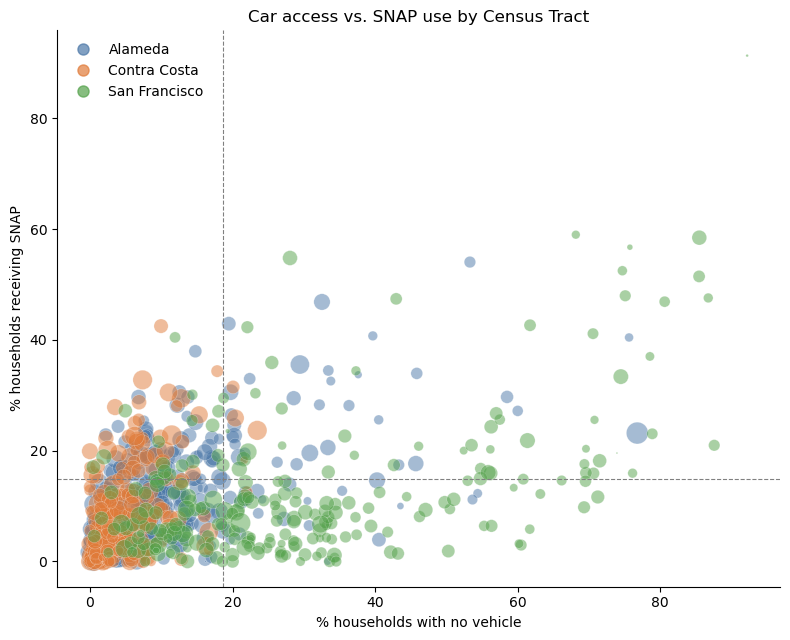

In [10]:
colors = {
    "Alameda": "#4c78a8",
    "Contra Costa": "#e07b39",
    "San Francisco": "#54a24b",
}

fig, ax = plot_grouped_scatter(
    viz,
    x="pct_no_vehicle",
    y="pct_snap",
    group_col="county_name",
    colors=colors,
    size_col="total_pop",
    size_scale=40,
    quantile=0.75,
)

ax.set_xlabel("% households with no vehicle")
ax.set_ylabel("% households receiving SNAP")
ax.set_title("Car access vs. SNAP use by Census Tract")

fig.tight_layout()
plt.savefig('outputs/Car_Access_vs_SNAP.png')
plt.show()

#### Top right quadrant highlights attention on where there is a high percent of households with no vehicle and that receive SNAP, specifically the tracts in Alameda and SF. Note: might help to make this chart interactive in the future, since it could help identify each tract and its characteristics as well.

## Food-store cleaning and access
#### This cell reads in the bay area tract information.

In [11]:
tracts = pd.read_csv('data/selected_bay_tracts', dtype={'geoid': str}) # file created by hafsa!
tracts['geometry'] = tracts['geometry'].apply(
    lambda x: wkt.loads(x) if isinstance(x, str) else x
)
tract_gdf = gpd.GeoDataFrame(
    tracts, geometry='geometry', crs='EPSG:4326'
)
print('total number of tracts read in: ', len(tract_gdf))

# filtering for only San Francisco, Alameda, and Contra Costa.
sf = tract_gdf[tract_gdf['geoid'].str[:5] == '06075']
sf = sf[sf['geoid'] != '06075980401'] # remove the island off the coast
contra_costa = tract_gdf[tract_gdf['geoid'].str[:5] == '06013']
alameda = tract_gdf[tract_gdf['geoid'].str[:5] == '06001']
bay = gpd.GeoDataFrame(pd.concat([sf,contra_costa,alameda], ignore_index=True), crs=sf.crs) # turn to geopandas df
bay.to_csv('data/bay_tracts.csv', index=False) # saving for future use
print('total number of tracts included in analysis: ', len(bay))

total number of tracts read in:  1768
total number of tracts included in analysis:  862


#### This cell does the dirty work for stores (found with google maps API), filtering out unwanted store types and fixing several incorrect classifications. The results are plotted over a map of SF and the East Bay.

In [12]:
# load in bay data again, convert to proper EPSG
bay = pd.read_csv('data/bay_tracts.csv', dtype={'geoid': str})
bay_4326 = gpd.GeoDataFrame(bay, geometry=gpd.GeoSeries.from_wkt(bay['geometry']),crs="EPSG:4326")

# load in store data, convert to proper EPSG
stores = pd.read_csv('data/bay_food_places.csv', dtype={'place_id': str, 'name': str, 'found_by': str,})
stores_4326 = gpd.GeoDataFrame(stores, geometry=gpd.GeoSeries.from_wkt(stores['geometry']),crs="EPSG:4326")
print('total number of stores read in: ', len(stores_4326))

grocer_and_convinience = stores_4326[stores_4326['primary_type'].isin(['asian_grocery_store', 'grocery_store', 'convenience_store',
       'market', 'gas_station', 'deli', 'liquor_store', 'farmers_market',
       'drugstore', 'supermarket', 'health_food_store', 'food_store',
       'store', 'wholesaler', 'supplier', 'butcher_shop',
       'hypermarket', 'food'])]
print('total number of stores after filtering: ', len(grocer_and_convinience))

grocer_and_convinience = grocer_and_convinience[grocer_and_convinience['business_status'] == 'OPERATIONAL']
grocer_and_convinience = grocer_and_convinience[~grocer_and_convinience['name'].str.lower().str.contains('smoke|vape|vitamin|cigar')]
grocer_and_convinience = grocer_and_convinience[~grocer_and_convinience['name'].isin(['Natural Haven Co', 'Afikomen Judaica', 'Summer Solace Tallow', 'Llewellyn Marine Supply, Inc', 'The Caviar Co.', "Mooney's", 'Twisted Thistle Apothecary', "Dave's Gourmet"])]
grocer_and_convinience.loc[grocer_and_convinience['name'] == "Sam's Club", 'primary_type'] = 'grocery_store'
grocer_and_convinience.loc[grocer_and_convinience['name'] == "Roxy Trading Inc", 'primary_type'] = 'grocery_store'
print('total number of stores after removal of unrelated types ', len(grocer_and_convinience))

#remove duplicates
grocer_and_convinience = grocer_and_convinience.drop_duplicates(subset=['name', 'address'])
print('total number of stores after dedepulication: ', len(grocer_and_convinience))

liquor_stores = pd.concat([
    grocer_and_convinience[grocer_and_convinience['primary_type'].isin(['liquor_store'])],
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'deli') & (grocer_and_convinience['primary_search_type'] == 'liquor_store')],
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'market') & (grocer_and_convinience['primary_search_type'] == 'liquor_store')],
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'store') & (grocer_and_convinience['primary_search_type'] == 'liquor_store')],
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'wholesaler') & (grocer_and_convinience['primary_search_type'] == 'liquor_store')]],
    ignore_index = True
)
convinience_stores = pd.concat([
    grocer_and_convinience[grocer_and_convinience['primary_type'].isin(['convenience_store','gas_station', 'drugstore'])],
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'deli') & (grocer_and_convinience['primary_search_type'] == 'convenience_store')],
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'market') & (grocer_and_convinience['primary_search_type'] == 'convenience_store')],
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'store') & (grocer_and_convinience['primary_search_type'] == 'convenience_store')],
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'wholesaler') & (grocer_and_convinience['primary_search_type'] == 'convenience_store')]],
    ignore_index = True
)
grocery_stores = pd.concat([
    grocer_and_convinience[grocer_and_convinience['primary_type'].isin(['asian_grocery_store', 'grocery_store', 'farmers_market', 'supermarket', 'health_food_store', 'food_store', 'butcher_shop', 'hypermarket', 'food'])],
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'deli') & (grocer_and_convinience['primary_search_type'] == 'grocery_store')],
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'market') & (grocer_and_convinience['primary_search_type'] == 'grocery_store')], 
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'store') & (grocer_and_convinience['primary_search_type'] == 'grocery_store')],  
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'wholesaler') & (grocer_and_convinience['primary_search_type'] == 'grocery_store')]],
    ignore_index = True
)

# some checks
print('number of liquor stores: ', len(liquor_stores))
print('number of convinience stores: ', len(convinience_stores))
print('number of grocery stores: ', len(grocery_stores))
print('excluded?: ', len(grocer_and_convinience) - (sum([len(liquor_stores), len(convinience_stores), len(grocery_stores)])))
included = pd.concat([grocery_stores, convinience_stores, liquor_stores], ignore_index = True)
check = pd.merge(grocer_and_convinience, included, on='place_id', how='outer', indicator='merge_label')
excluded = check[~(check['merge_label'] == 'both')]
excluded = excluded.drop(excluded.loc[:, "name_y":"geometry_y"].columns, axis=1)
print('excluded types?: ', excluded['primary_type_x'].unique())

total number of stores read in:  3350
total number of stores after filtering:  3066
total number of stores after removal of unrelated types  2915
total number of stores after dedepulication:  2911
number of liquor stores:  669
number of convinience stores:  890
number of grocery stores:  1352
excluded?:  0
excluded types?:  []


#### To find what food accessibility metrics differentiate neighborhoods the most across the Bay, we will first discretize census tracts into points 500 meters apart on a grid, a method similar to one previously used to sample every census tract at least once. Eventually, for each point, we will define ‘walking distance’ as a walk that takes 15 minutes or less according to Google Maps, ‘biking distance’ as a trip taking 30 minutes or less by bicycle, and ‘transit distance’ as a trip taking 30 minutes or less by transit according to Google Maps. However, for this first pass, we will use using the buffer method: create a radius around each point and sample how many stores are in walking and driving distance. This is an approximation of the results we expect to find when using actual travel time.

#### The grid is plotted over the bay area for reference of the sampling density.

,geometry,geoid,countyfp,tract,stores_walk_all,stores_drive_all,stores_walk_liquor,stores_drive_liquor,stores_walk_convenience,stores_drive_convenience,stores_walk_grocery,stores_drive_grocery
505,POINT (542858.386 4180801.584),06075047904,75,47904,3,314,1,92,0,76,2,146
506,POINT (542858.386 4181301.584),06075047904,75,47904,3,310,1,88,0,73,2,149
507,POINT (542858.386 4181801.584),06075047904,75,47904,0,309,0,88,0,74,0,147
642,POINT (543358.386 4176801.584),06075035400,75,35400,2,333,2,92,0,85,0,156
643,POINT (543358.386 4177301.584),06075035400,75,35400,1,356,1,98,0,88,0,170


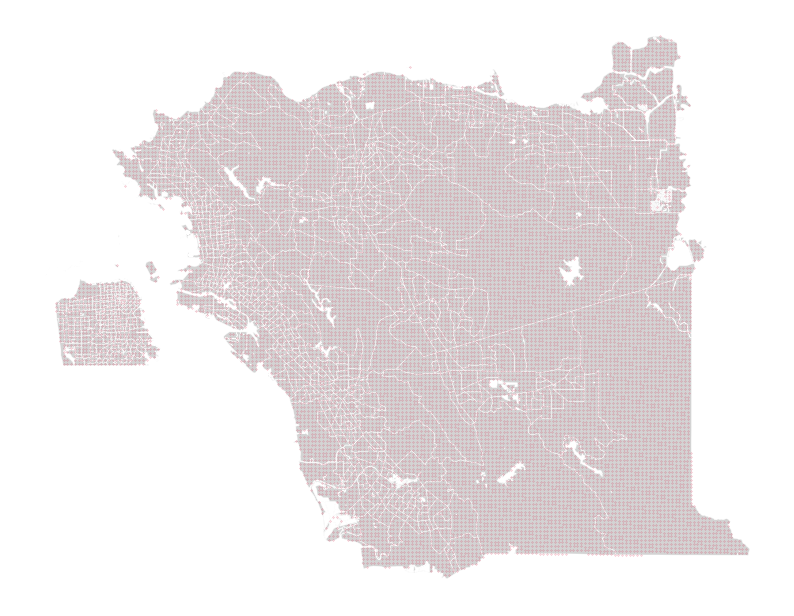

In [13]:
from shapely.geometry import Point
from scipy.spatial import cKDTree

# Set distances
MILE = 1609.344 #meters
WALK  = 0.5 * MILE  # walking distance
DRIVE = 5 * MILE   # driving distance
spacing = 500 # half a kilometer, 0.3 miles

bay_meters = bay_4326.to_crs(epsg=26910) # move to meters to make grid points

# make the grid
minx, miny, maxx, maxy = bay_meters.total_bounds
x_coords = np.arange(minx, maxx, spacing)
y_coords = np.arange(miny, maxy, spacing)
points = [Point(x, y) for x in x_coords for y in y_coords]

# overlay it with the bay tracts
grid_gpd = gpd.GeoDataFrame({'geometry': points}, crs='EPSG:26910')
grid_gpd = gpd.sjoin(grid_gpd, bay_meters, predicate='within') # spatial join!

def count_within(points, stores, radius):
    """For each point, count the stores inside a circle of `radius` meters around it."""
    stores = stores.to_crs(points.crs)
    tree = cKDTree(np.c_[stores.geometry.x, stores.geometry.y])
    return tree.query_ball_point(np.c_[points.geometry.x, points.geometry.y],
                                 radius, return_length=True)

store_dfs = {
    'all': grocer_and_convinience,
    'liquor': liquor_stores,
    'convenience': convinience_stores,
    'grocery': grocery_stores
}

# do the counting!
for name, df in store_dfs.items():
    grid_gpd[f'stores_walk_{name}'] = count_within(grid_gpd, df, WALK)
    grid_gpd[f'stores_drive_{name}'] = count_within(grid_gpd, df, DRIVE)

# 500 meter spacing, plotted
ax = bay_4326.plot(color="lightgrey", edgecolor="white", linewidth=0.3, figsize=(10, 10))
grid_gpd.to_crs(epsg=4326).plot(ax=ax, markersize=0.05, color="crimson", alpha=0.6)
ax.set_axis_off()
plt.savefig("outputs/adaptive_grid.png", dpi=200, bbox_inches="tight")

grid_gpd = grid_gpd.drop(columns=['index_right', 'Unnamed: 0'], errors='ignore')
grid_gpd.head()

#### Next, we'll find the average number of stores in walking and driving distance for each tract by averaging the number of stores found above by grouped geoid. Then we'll plot the results for comparison.

In [14]:
#all stores
avg_all_stores = grid_gpd.groupby('geoid')[['stores_walk_all', 'stores_drive_all']].mean().reset_index()
avg_all_stores['geoid'] = avg_all_stores['geoid'].astype('str')
tracts_avg_all_stores = bay_meters.merge(avg_all_stores, on = 'geoid', how = 'left')

#liquor stores
avg_liquor_stores = grid_gpd.groupby('geoid')[['stores_walk_liquor', 'stores_drive_liquor']].mean().reset_index()
avg_liquor_stores['geoid'] = avg_liquor_stores['geoid'].astype('str')
tracts_avg_liquor_stores = bay_meters.merge(avg_liquor_stores, on = 'geoid', how = 'left')

#convenience stores
avg_convenience_stores = grid_gpd.groupby('geoid')[['stores_walk_convenience', 'stores_drive_convenience']].mean().reset_index()
avg_convenience_stores['geoid'] = avg_convenience_stores['geoid'].astype('str')
tracts_avg_convenience_stores = bay_meters.merge(avg_convenience_stores, on = 'geoid', how = 'left')

#grocery stores
avg_grocery_stores = grid_gpd.groupby('geoid')[['stores_walk_grocery', 'stores_drive_grocery']].mean().reset_index()
avg_grocery_stores['geoid'] = avg_grocery_stores['geoid'].astype('str')
tracts_avg_grocery_stores = bay_meters.merge(avg_grocery_stores, on = 'geoid', how = 'left')

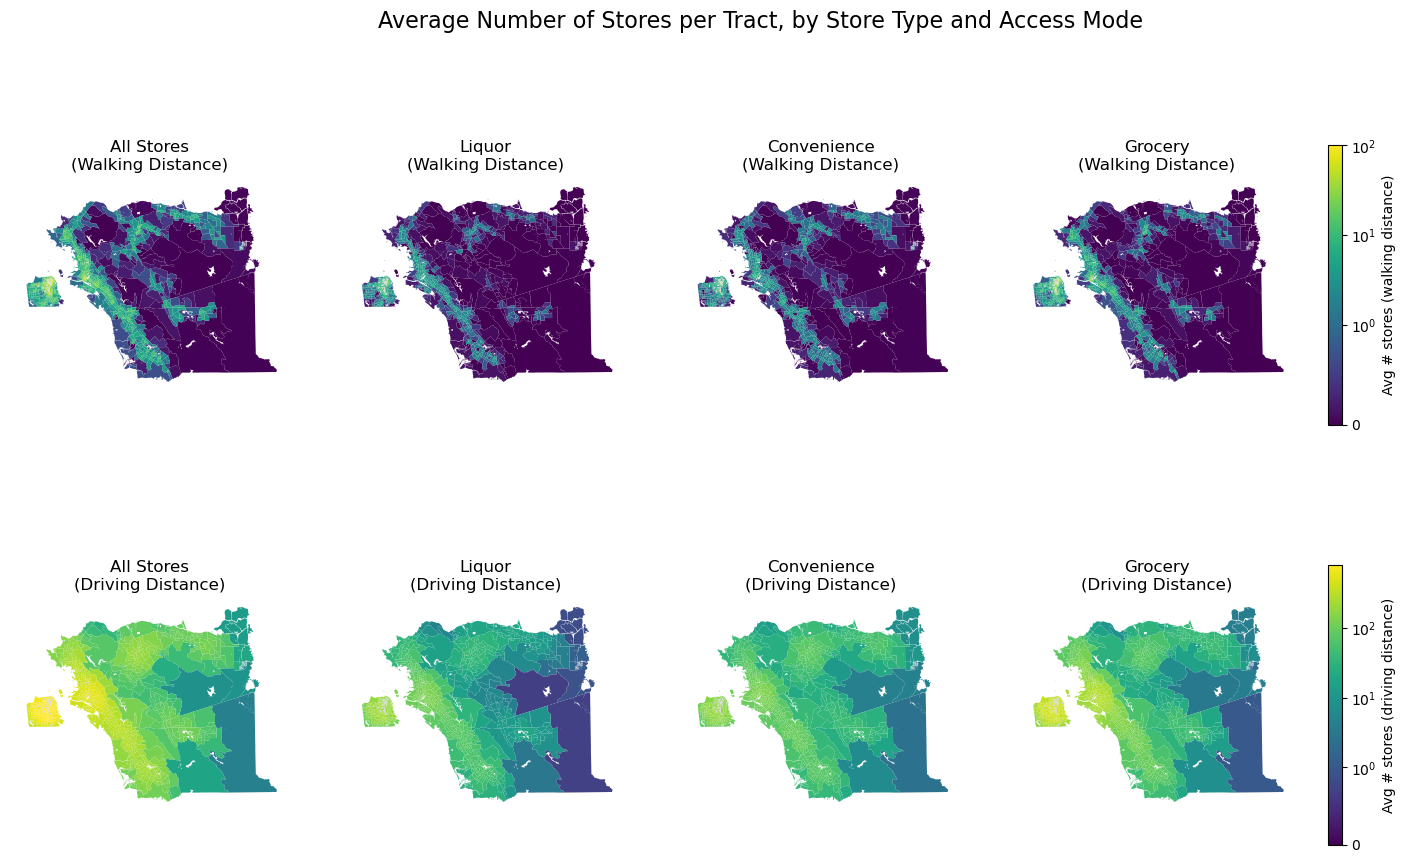

In [15]:
# chlorpleth
from matplotlib.colors import SymLogNorm

# (label, dataframe, column suffix)
layers = [
    ('All Stores',  tracts_avg_all_stores,         'all'),
    ('Liquor',      tracts_avg_liquor_stores,      'liquor'),
    ('Convenience', tracts_avg_convenience_stores, 'convenience'),
    ('Grocery',     tracts_avg_grocery_stores,     'grocery'),
]
modes = {'walk': 'Walking Distance', 'drive': 'Driving Distance'}

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

for row, (mode, mode_label) in enumerate(modes.items()):
    vmax = max(df[f'stores_{mode}_{suffix}'].max() for _, df, suffix in layers)
    norm = SymLogNorm(linthresh=1, vmin=0, vmax=vmax) # used to make the color scale similar to a log scale, but able to handle 0s

    for col, (label, df, suffix) in enumerate(layers):
        ax = axes[row, col]
        df.plot(ax=ax, column=f'stores_{mode}_{suffix}',
                norm=norm, cmap='viridis',
                missing_kwds={'color': 'lightgrey'})
        ax.set_title(f'{label}\n({mode_label})')
        ax.set_axis_off()

    sm = mpl.cm.ScalarMappable(norm=norm, cmap='viridis')
    fig.colorbar(sm, ax=axes[row, :], shrink=0.8, pad=0.02,
                 label=f'Avg # stores ({mode_label.lower()})')

fig.suptitle('Average Number of Stores per Tract, by Store Type and Access Mode', fontsize=16)

fig.savefig("outputs/store_access_choropleths.png", dpi=300, bbox_inches="tight")
plt.show()

## Cultural food access

In [16]:
acs = pd.read_csv(
    "data/cultural_food_census.csv",
    dtype={"geoid": "string"}
)

acs.head()

,Unnamed: 0,GEO_ID,B01003_001E,B03003_003E,B02015_007E,B02015_008E,B02015_011E,B02015_012E,B02015_002E,B02015_003E,...,total_pop,n_hispanic,n_east_asian,n_south_asian,n_muslim_estimate,pct_hispanic,pct_east_asian,pct_south_asian,pct_muslim_estimate,poverty_rate
0,0,1400000US06001400100,3132,214,0,0,0,0,302,0,...,3132,214,0,302,0,0.068327,0.000000,0.096424,0.000000,0.041960
1,1,1400000US06001400200,2203,202,0,8,0,42,88,0,...,2203,202,50,88,12,0.091693,0.022696,0.039946,0.005447,0.077167
2,2,1400000US06001400300,5990,571,0,30,0,79,126,0,...,5990,571,109,126,101,0.095326,0.018197,0.021035,0.016861,0.042824
3,3,1400000US06001400400,4399,509,0,49,0,56,103,0,...,4399,509,105,116,12,0.115708,0.023869,0.026370,0.002728,0.079898
4,4,1400000US06001400500,3579,636,0,6,0,23,50,0,...,3579,636,29,56,0,0.177703,0.008103,0.015647,0.000000,0.110551


In [17]:
### Finalizing GDF
tracts = pd.read_csv('data/bay_tracts.csv', dtype = "str") 
tracts["geometry"] = tracts["geometry"].apply(shapely.wkt.loads)
gdf = gpd.GeoDataFrame(tracts, geometry = "geometry", crs="EPSG:4326")

food_locations = pd.read_csv('data/bay_food_places.csv')
stores_gdf = gpd.GeoDataFrame(
    food_locations,
    geometry=[Point(xy) for xy in zip(food_locations["lon"], food_locations["lat"])],
    crs="EPSG:4326",
)

bay_gdf = gdf.merge(acs, on="geoid", how="left", validate="one_to_one")
bay_gdf.columns

Index(['geoid', 'countyfp', 'tract_x', 'geometry', 'Unnamed: 0', 'GEO_ID',
       'B01003_001E', 'B03003_003E', 'B02015_007E', 'B02015_008E',
       'B02015_011E', 'B02015_012E', 'B02015_002E', 'B02015_003E',
       'B02015_016E', 'B02015_017E', 'B02015_018E', 'B04006_007E',
       'B04006_008E', 'B04006_009E', 'B04006_011E', 'B04006_012E',
       'B17001_001E', 'B17001_002E', 'state', 'county', 'tract_y',
       'county_name', 'total_pop', 'n_hispanic', 'n_east_asian',
       'n_south_asian', 'n_muslim_estimate', 'pct_hispanic', 'pct_east_asian',
       'pct_south_asian', 'pct_muslim_estimate', 'poverty_rate'],
      dtype='object')

#### We will first remove all the food locations that are not food related or are restaurants.

#### Then, we need to figure out which of the store locations in our dataset pertains to each category that we want to examine. So we will parse through the primary type and types columns of the food_locations dataframe to categorize each store based on value, cultural produce, and dietary needs. We will also parse through based on key terms in the name of the location. We will split up the words in the name and select words that appear frequently. There are limitations to this method. Locations that have names originating from Spanish can often be miscategorized as Hispanic stores. This is frankly, a significant issue given our analysis of the state of CA, a state known to have a significant history involving Spanish speakers.

#### There are terms that do not specify anything and are too generic. For those, we will not use those terms are classifiers.

#### While we can find all possible types listed in the columns, we do not have particularly easy way to go through every variety and label it as indicitive of a column. Therefore, we will be randomly sampling from the table, going through the possible types and adding them to whichever label they may indicate. The terms used to parse through premium vs typical stores will be based on prior general knowledge.   

#### #Focusing on cultural foods for now
#### We are condensing cultural foods into hispanic, Chinese / East Asian, South Asian, and Halal.

#### We are condensing vegan and vegatarian together, because stores that have the fresh vegetables and produce that is required for veganism, typically also have the dairy and eggs that become allowed through vegetarianism.
#### It is important to note that there are potential errors in this method. Because we are parsing through grocery names and categories with key terms, there is a likelihood that there could be misclassifications.

In [18]:
HISPANIC_NAME_TERMS = [
    "ahorro", "mercado", "tienda", "carniceria", "rancho",
    "tierra", "latina", "supermercado", "mexican", "chico"
]
HISPANIC_TYPES = [
    "mexican_grocery_store", "latin_american_grocery_store",
]

CHINESE_EASTASIAN_NAME_TERMS = [
    "china", "h-mart", "asian", "chinese", "wing", "sheng",
    "tian", "kee", "h mart", "99 ranch", "filipino"
]
#there is a type for asian_grocery_store, but it causes overlap with south asian locations, 
#can sometimes consider south asian as east asian
CHINESE_EASTASIAN_TYPES = [
    "asian_grocery_store", "chinese_grocery_store",
    "korean_grocery_store", "japanese_grocery_store",
    "vietnamese_grocery_store", "filipino_grocery_store",
]

SOUTH_ASIAN_NAME_TERMS = [
    "india", "indian", "namaste", "bharat",
    "bazar", "nepal", "punjabi", "coconut hill"
]
SOUTH_ASIAN_TYPES = [
    "indian_grocery_store", "pakistani_grocery_store",
]

HALAL_NAME_TERMS = [
    "halal", "kabul", "afghan", "zamzam",
    "madni", "jazeera", "salam", "mediterranean", "naseeb"
]
HALAL_TYPES = [
    "middle_eastern_grocery_store", "halal_grocery_store",
    "halal_butcher_shop",
]

def name_matches(name, terms):
    if not isinstance(name, str):
        return False
    lowercase_name = name.lower()
    for term in terms:
        if term in lowercase_name:
            return True
    return False


def tags_match(tags, type_list):
    for tag in type_list:
        if tag in tags:
            return True
    return False


def classify_culture(row):
    tags = [tag.strip() for tag in str(row["types"]).split(",")]
    tags.append(row["primary_type"])

    name = row["name"]

    hispanic = (name_matches(name, HISPANIC_NAME_TERMS) or tags_match(tags, HISPANIC_TYPES))
    chinese_eastasian = (name_matches(name, CHINESE_EASTASIAN_NAME_TERMS) or tags_match(tags, CHINESE_EASTASIAN_TYPES))
    south_asian = (name_matches(name, SOUTH_ASIAN_NAME_TERMS) or tags_match(tags, SOUTH_ASIAN_TYPES))
    muslim = (name_matches(name, HALAL_NAME_TERMS) or tags_match(tags, HALAL_TYPES))

    return pd.Series({"hispanic": hispanic, "chinese_eastasian": chinese_eastasian, "south_asian": south_asian, "muslim": muslim,})

CULTURAL_COLS = ["hispanic", "chinese_eastasian", "south_asian", "muslim"]
classified_cultural_cols = stores_gdf.apply(classify_culture, axis=1)
for col in CULTURAL_COLS:
    stores_gdf[col] = classified_cultural_cols[col]
CULTURAL_COLS = ["hispanic", "chinese_eastasian", "south_asian", "muslim"]

print(stores_gdf[CULTURAL_COLS].sum())

hispanic              66
chinese_eastasian    227
south_asian           48
muslim                27
dtype: int64


In [19]:
### CLASSIFYING FOOD LOCATIONS

# Using arbitrary thresholds
MIN_PERCENT = 0.05
MIN_POP = 250
bay_gdf["hispanic_tract"] = (
    (bay_gdf["pct_hispanic"] >= MIN_PERCENT) & (bay_gdf["n_hispanic"] >= MIN_POP)
)
bay_gdf["east_asian_tract"] = (
    (bay_gdf["pct_east_asian"] >= MIN_PERCENT) & (bay_gdf["n_east_asian"] >= MIN_POP)
)
bay_gdf["south_asian_tract"] = (
    (bay_gdf["pct_south_asian"] >= MIN_PERCENT) & (bay_gdf["n_south_asian"] >= MIN_POP)
)
bay_gdf["muslim_est_tract"] = (
    (bay_gdf["pct_muslim_estimate"] >= MIN_PERCENT) & (bay_gdf["n_muslim_estimate"] >= MIN_POP)
)
bay_gdf

,geoid,countyfp,tract_x,geometry,Unnamed: 0,GEO_ID,B01003_001E,B03003_003E,B02015_007E,B02015_008E,...,n_muslim_estimate,pct_hispanic,pct_east_asian,pct_south_asian,pct_muslim_estimate,poverty_rate,hispanic_tract,east_asian_tract,south_asian_tract,muslim_est_tract
0,06075010101,75,10101,"MULTIPOLYGON (((-122.42024 37.80963, -122.4202...",621,1400000US06075010101,1911,373,0,0,...,0,0.195186,0.010466,0.172684,0.000000,0.195709,True,False,True,False
1,06075010102,75,10102,"POLYGON ((-122.4169 37.80522, -122.41525 37.80...",622,1400000US06075010102,1917,112,0,11,...,45,0.058425,0.018779,0.300469,0.023474,0.080856,False,False,True,False
2,06075010201,75,10201,"POLYGON ((-122.42485 37.80227, -122.42467 37.8...",623,1400000US06075010201,2650,344,0,0,...,0,0.129811,0.008679,0.010566,0.000000,0.068302,True,False,False,False
3,06075010202,75,10202,"POLYGON ((-122.42485 37.80227, -122.42487 37.8...",624,1400000US06075010202,1839,51,0,0,...,12,0.027732,0.000000,0.047308,0.006525,0.124587,False,False,False,False
4,06075010300,75,10300,"POLYGON ((-122.41873 37.80594, -122.41839 37.8...",625,1400000US06075010300,3824,435,0,0,...,19,0.113755,0.005753,0.114017,0.004969,0.094404,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
857,06001451704,1,451704,"POLYGON ((-121.79853 37.65616, -121.79853 37.6...",373,1400000US06001451704,4564,720,0,0,...,51,0.157756,0.017748,0.042507,0.011174,0.041849,True,False,False,False
858,06001981900,1,981900,"POLYGON ((-122.31221 37.79544, -122.31734 37.7...",374,1400000US06001981900,33,0,0,0,...,0,0.000000,0.000000,0.000000,0.000000,0.000000,False,False,False,False
859,06001982000,1,982000,"POLYGON ((-122.29603 37.79339, -122.30553 37.7...",375,1400000US06001982000,54,0,0,0,...,0,0.000000,0.000000,0.500000,0.000000,0.000000,False,False,False,False
860,06001982100,1,982100,"POLYGON ((-122.26638 37.87411, -122.26634 37.8...",376,1400000US06001982100,1104,184,0,33,...,50,0.166667,0.049819,0.077899,0.045290,0.354839,False,False,False,False


hispanic               66 stores (flag on stores_gdf)
chinese_eastasian     227 stores (flag on stores_gdf)
south_asian            48 stores (flag on stores_gdf)
muslim                 27 stores (flag on stores_gdf)


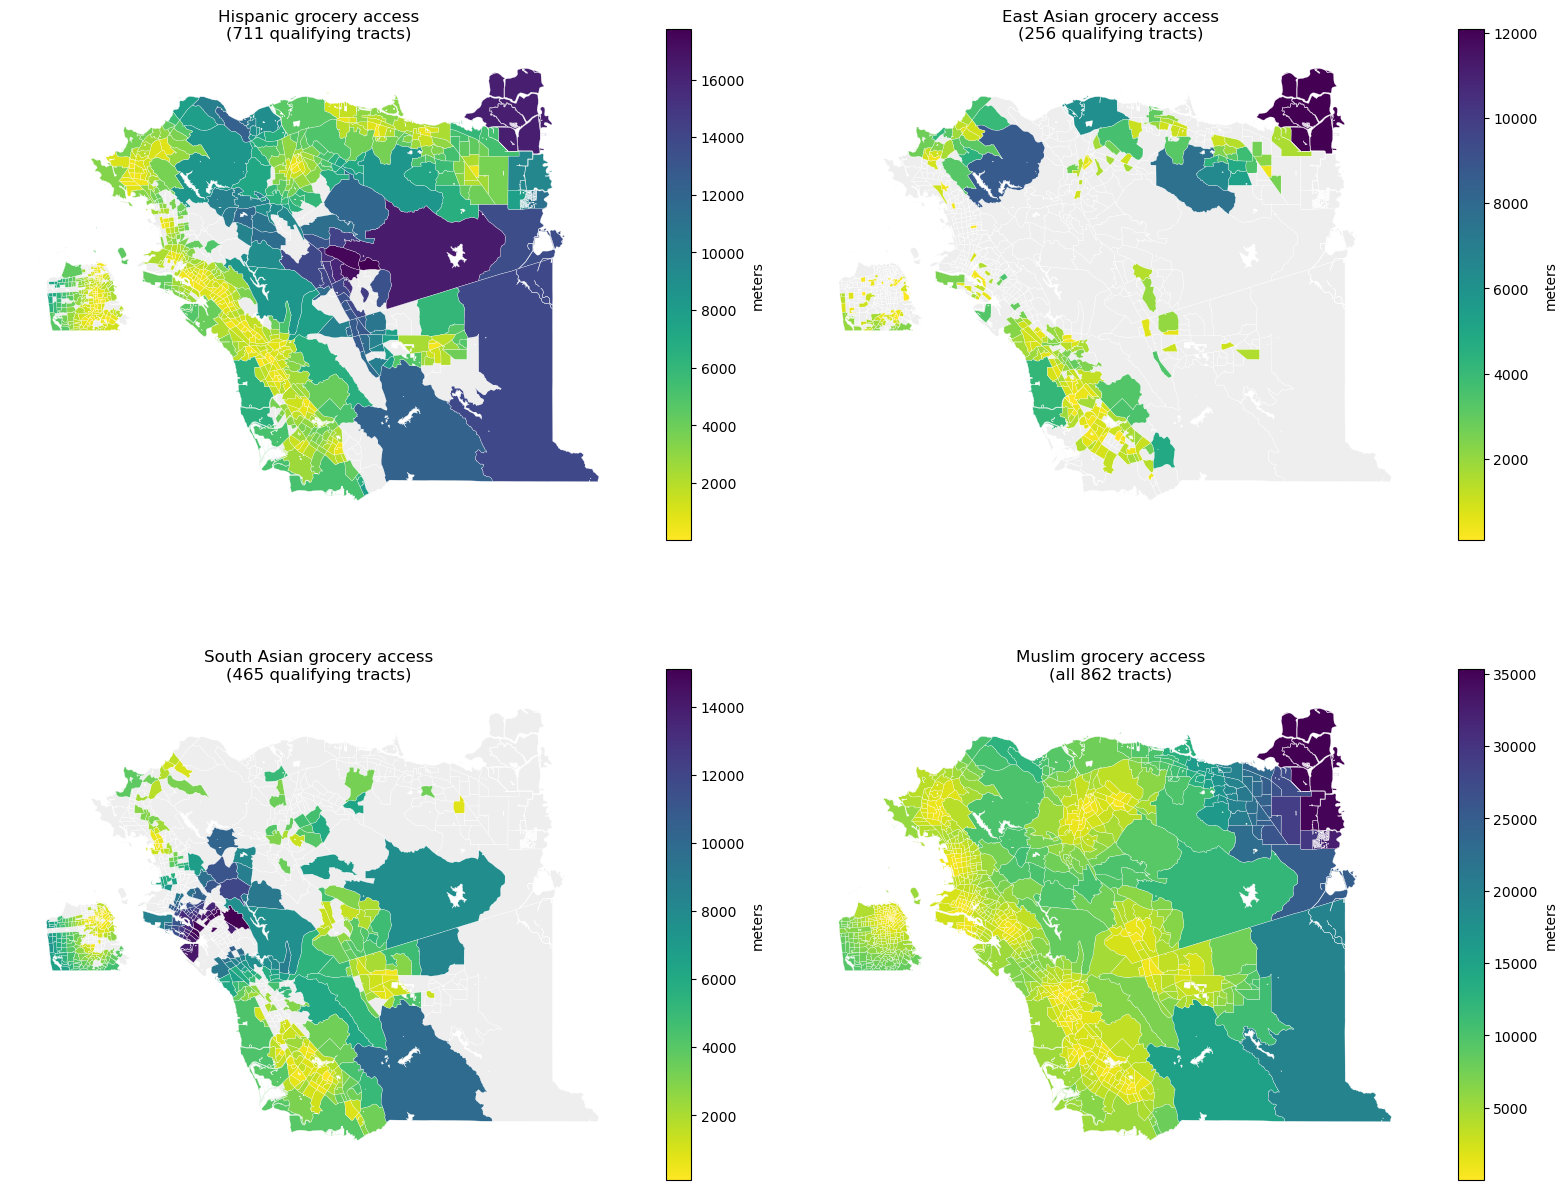

In [20]:
bay_gdf["geometry_center"] = bay_gdf.geometry.representative_point()

def tract_distance(stores_types, gdf, colname):
    tracts_crs3310 = gdf.copy().to_crs(3310)
    centers = gdf.set_geometry("geometry_center").to_crs(3310)
    tracts_crs3310 = gpd.GeoDataFrame(tracts_crs3310[["geoid"]], geometry=centers.geometry, crs=3310)
    stores_crs3310 = stores_types.to_crs(3310)
    nearest = gpd.sjoin_nearest(tracts_crs3310[["geoid", "geometry"]], stores_crs3310[["name", "geometry"]], 
                                how="left", distance_col="dist_m")
    
    return nearest.groupby("geoid")["dist_m"].min().reindex(gdf["geoid"]).rename(colname)

for flag in ["hispanic", "chinese_eastasian", "south_asian", "muslim"]:
    print(f"{flag:20s} {stores_gdf[flag].sum():4d} stores (flag on stores_gdf)" if flag in stores_gdf.columns else f"{flag:20s} MISSING")

CULTURAL_DIST = [
    ("hispanic",          "dist_hispanic_cultural"),
    ("chinese_eastasian", "dist_east_asian_cultural"),
    ("south_asian",       "dist_south_asian_cultural"),
    ("muslim",            "dist_muslim_cultural"),
]

for store_flag, dist_col in CULTURAL_DIST:
    subset = stores_gdf[stores_gdf[store_flag]]
    dist = tract_distance(subset, bay_gdf, dist_col).reset_index()

    # Idempotent: drop before merge
    if dist_col in bay_gdf.columns:
        bay_gdf = bay_gdf.drop(columns=dist_col)

    bay_gdf = bay_gdf.merge(dist, on="geoid", how="left")

CULTURAL_MAPS = [
    ("Hispanic grocery access",
     "dist_hispanic_cultural",     "hispanic_tract"),
    ("East Asian grocery access",
     "dist_east_asian_cultural",   "east_asian_tract"),
    ("South Asian grocery access",
     "dist_south_asian_cultural",  "south_asian_tract"),
    ("Muslim grocery access",
     "dist_muslim_cultural",       None) #Need to find a better estimate method, not enough tracts so no filter
]

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.flatten()   # 2×2 -> 4-item array

for ax, (title, dist_col, flag_col) in zip(axes, CULTURAL_MAPS):
    bay_gdf.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.3)

    use_all_tracts = (
        flag_col is None
        or flag_col not in bay_gdf.columns
        or bay_gdf[flag_col].sum() == 0
    )

    if use_all_tracts:
        bay_gdf.plot(
            ax=ax, column=dist_col, cmap="viridis_r",
            legend=True, legend_kwds={"label": "meters", "shrink": 0.7},
            edgecolor="white", linewidth=0.2,
        )
        ax.set_title(f"{title}\n(all {len(bay_gdf)} tracts)", fontsize=12)
    else:
        q = bay_gdf[bay_gdf[flag_col]]
        q.plot(
            ax=ax, column=dist_col, cmap="viridis_r",
            legend=True, legend_kwds={"label": "meters", "shrink": 0.7},
            edgecolor="white", linewidth=0.2,
        )
        ax.set_title(f"{title}\n({len(q)} qualifying tracts)", fontsize=12)

    ax.set_axis_off()

plt.tight_layout()
plt.savefig("outputs/cultural_access_maps_2x2.png", dpi=150, bbox_inches="tight")
plt.show()

#### The above graph showcases distance (in meters) from each tract's centroid to the nearest culturally-specific grocery store.

## Public-health estimates and selected EDA

### Health Indicators EDA
- This notebook examines the CDC PLACES health estimates for selected Bay Area tracts.

In [21]:
health = pd.read_csv("data/health_by_tract.csv", dtype={"GEOID": "string"})
health.head()

,GEOID,countyfips,countyname,coronary_heart_disease,coronary_heart_disease_lcl,coronary_heart_disease_ucl,diabetes,diabetes_lcl,diabetes_ucl,high_blood_pressure,high_blood_pressure_lcl,high_blood_pressure_ucl,obesity,obesity_lcl,obesity_ucl,stroke,stroke_lcl,stroke_ucl
0,06001400100,6001,Alameda,5.6,5.0,6.4,9.8,8.6,11.4,31.7,28.6,35.2,20.5,17.1,24.6,2.8,2.5,3.1
1,06001400200,6001,Alameda,4.7,4.1,5.4,7.9,6.8,9.2,27.1,24.2,30.3,21.7,18.1,26.0,2.3,2.1,2.7
2,06001400300,6001,Alameda,4.1,3.6,4.7,7.8,6.7,9.0,26.3,23.5,29.3,22.8,19.1,26.9,2.3,2.0,2.6
3,06001400400,6001,Alameda,3.6,3.2,4.1,6.9,6.0,8.0,23.8,21.2,26.6,23.0,19.2,27.3,2.0,1.8,2.2
4,06001400500,6001,Alameda,3.6,3.2,4.1,7.8,6.8,8.9,25.1,22.4,28.0,25.5,21.3,30.2,2.2,2.0,2.5


In [22]:
selected = pd.read_csv("data/selected_bay_tracts", dtype={"geoid": "string"})

selected_tracts = gpd.GeoDataFrame(
    selected.drop(columns="geometry"),
    geometry=gpd.GeoSeries.from_wkt(
        selected["geometry"],
        crs="EPSG:4326"))

# Keep the same three counties as the food-access analysis and remove the tract
# excluded in the store-access notebook.
selected_tracts = selected_tracts.loc[
    selected_tracts["geoid"].str[:5].isin(["06001", "06013", "06075"])
    & (selected_tracts["geoid"] != "06075980401")
].copy()

# joining health estimates to the remaining selected tracts

bay_health = selected_tracts.merge(
    health,
    left_on="geoid",
    right_on="GEOID",
    how="left",
    validate="one_to_one")

bay_health.head(5)


,geoid,countyfp,tract,geometry,GEOID,countyfips,countyname,coronary_heart_disease,coronary_heart_disease_lcl,coronary_heart_disease_ucl,...,diabetes_ucl,high_blood_pressure,high_blood_pressure_lcl,high_blood_pressure_ucl,obesity,obesity_lcl,obesity_ucl,stroke,stroke_lcl,stroke_ucl
0,06001400100,1,400100,"POLYGON ((-122.24692 37.88536, -122.24666 37.8...",06001400100,6001.0,Alameda,5.6,5.0,6.4,...,11.4,31.7,28.6,35.2,20.5,17.1,24.6,2.8,2.5,3.1
1,06001400200,1,400200,"POLYGON ((-122.25794 37.84261, -122.25774 37.8...",06001400200,6001.0,Alameda,4.7,4.1,5.4,...,9.2,27.1,24.2,30.3,21.7,18.1,26.0,2.3,2.1,2.7
2,06001400300,1,400300,"POLYGON ((-122.26564 37.83764, -122.26558 37.8...",06001400300,6001.0,Alameda,4.1,3.6,4.7,...,9.0,26.3,23.5,29.3,22.8,19.1,26.9,2.3,2.0,2.6
3,06001400400,1,400400,"POLYGON ((-122.26184 37.84163, -122.26182 37.8...",06001400400,6001.0,Alameda,3.6,3.2,4.1,...,8.0,23.8,21.2,26.6,23.0,19.2,27.3,2.0,1.8,2.2
4,06001400500,1,400500,"POLYGON ((-122.26952 37.84859, -122.26938 37.8...",06001400500,6001.0,Alameda,3.6,3.2,4.1,...,8.9,25.1,22.4,28.0,25.5,21.3,30.2,2.2,2.0,2.5


### Exploratory Data Analysis

In [23]:
indicators = [
    "obesity",
    "diabetes",
    "coronary_heart_disease",
    "stroke",
    "high_blood_pressure",
]

diseases = {
    "Obesity": "obesity",
    "Diabetes": "diabetes",
    "Coronary heart disease": "coronary_heart_disease",
    "Stroke": "stroke",
    "High blood pressure": "high_blood_pressure"
}

bay_health[indicators]

,obesity,diabetes,coronary_heart_disease,stroke,high_blood_pressure
0,20.5,9.8,5.6,2.8,31.7
1,21.7,7.9,4.7,2.3,27.1
2,22.8,7.8,4.1,2.3,26.3
3,23.0,6.9,3.6,2.0,23.8
4,25.5,7.8,3.6,2.2,25.1
...,...,...,...,...,...
857,18.8,6.8,3.5,1.8,21.9
858,14.4,50.8,34.5,21.4,71.8
859,19.2,8.7,3.4,2.3,24.4
860,24.8,10.9,5.0,2.9,28.8


In [24]:
bay_health.loc[
    bay_health[indicators].isna().any(axis=1),
    ["geoid", "countyname"] + indicators]

,geoid,countyname,obesity,diabetes,coronary_heart_disease,stroke,high_blood_pressure
324,06001444303,NaN,NaN,NaN,NaN,NaN,NaN
374,06001981900,NaN,NaN,NaN,NaN,NaN,NaN
619,06013990000,NaN,NaN,NaN,NaN,NaN,NaN
861,06075990200,NaN,NaN,NaN,NaN,NaN,NaN


In [25]:
for title, column in diseases.items():
    print(title)
    display(
        bay_health.nlargest(5, column)[["GEOID", "countyname", column]]
    )

Obesity


,GEOID,countyname,obesity
597,06013379000,Contra Costa,42.3
104,06001409700,Alameda,39.6
412,06013307202,Contra Costa,39.1
595,06013377000,Contra Costa,39.0
405,06013305000,Contra Costa,38.2


Diabetes


,GEOID,countyname,diabetes
858,06075980501,San Francisco,50.8
629,06075010701,San Francisco,29.1
656,06075012502,San Francisco,28.0
843,06075061101,San Francisco,26.6
844,06075061102,San Francisco,25.0


Coronary heart disease


,GEOID,countyname,coronary_heart_disease
858,06075980501,San Francisco,34.5
856,06075980200,San Francisco,16.1
656,06075012502,San Francisco,15.1
526,06013351105,Contra Costa,13.8
629,06075010701,San Francisco,13.6


Stroke


,GEOID,countyname,stroke
858,06075980501,San Francisco,21.4
656,06075012502,San Francisco,8.8
629,06075010701,San Francisco,8.1
843,06075061101,San Francisco,7.3
24,06001402802,Alameda,7.1


High blood pressure


,GEOID,countyname,high_blood_pressure
858,06075980501,San Francisco,71.8
856,06075980200,San Francisco,56.2
526,06013351105,Contra Costa,54.4
523,06013351101,Contra Costa,50.9
656,06075012502,San Francisco,50.1


### Boxplots

#### For brevity, this report shows the certain plots as an example. We created the same plots for diabetes, coronary heart disease, stroke, and high blood pressure.

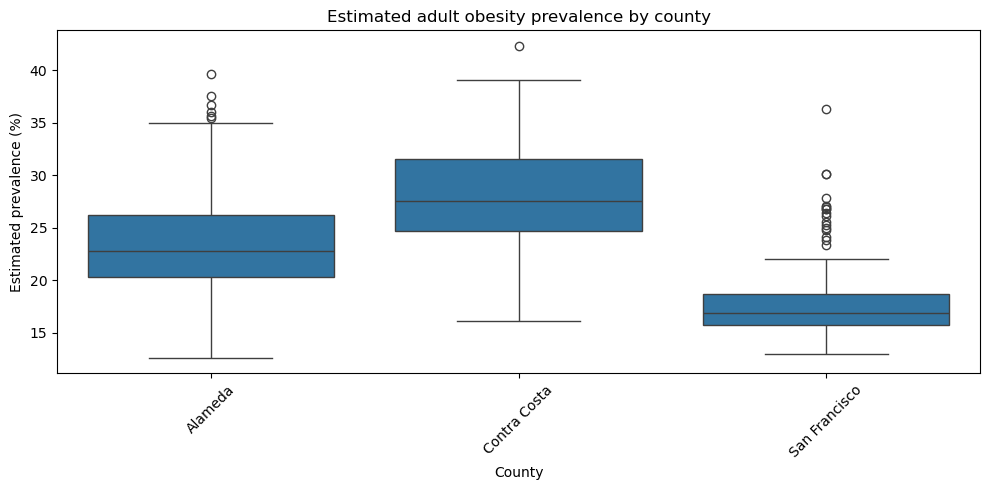

In [26]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=bay_health, x="countyname", y="obesity")
plt.xticks(rotation=45)
plt.xlabel("County")
plt.ylabel("Estimated prevalence (%)")
plt.title("Estimated adult obesity prevalence by county")
plt.savefig("outputs/obesity_boxplot.png", dpi=200, bbox_inches="tight")
plt.tight_layout()
plt.show()

### Health indicator distributions

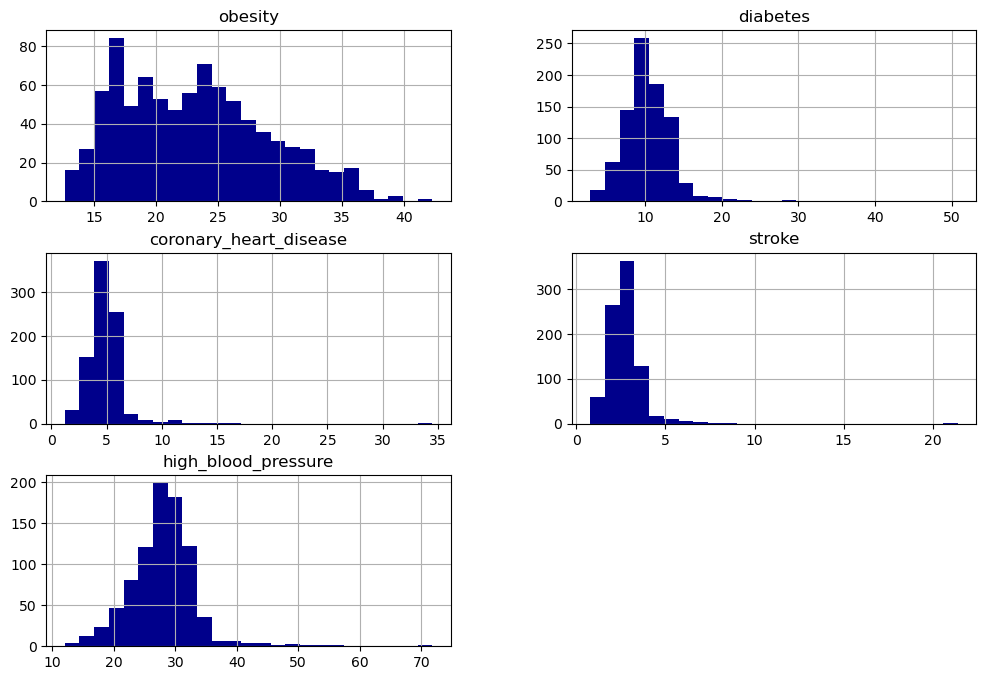

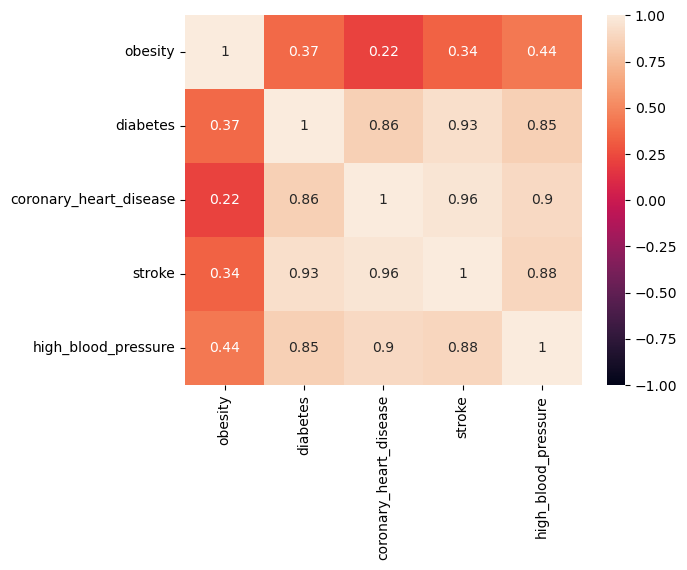

In [27]:
bay_health[indicators].hist(bins=25, figsize=(12, 8), color="darkblue")
plt.savefig("outputs/health_histograms.png", dpi=200, bbox_inches="tight")
plt.show()

sns.heatmap(
    bay_health[indicators].corr(),
    annot=True,
    vmin=-1,
    vmax=1
)
plt.savefig("outputs/health_correlation_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

### Maps of health estimated by tract

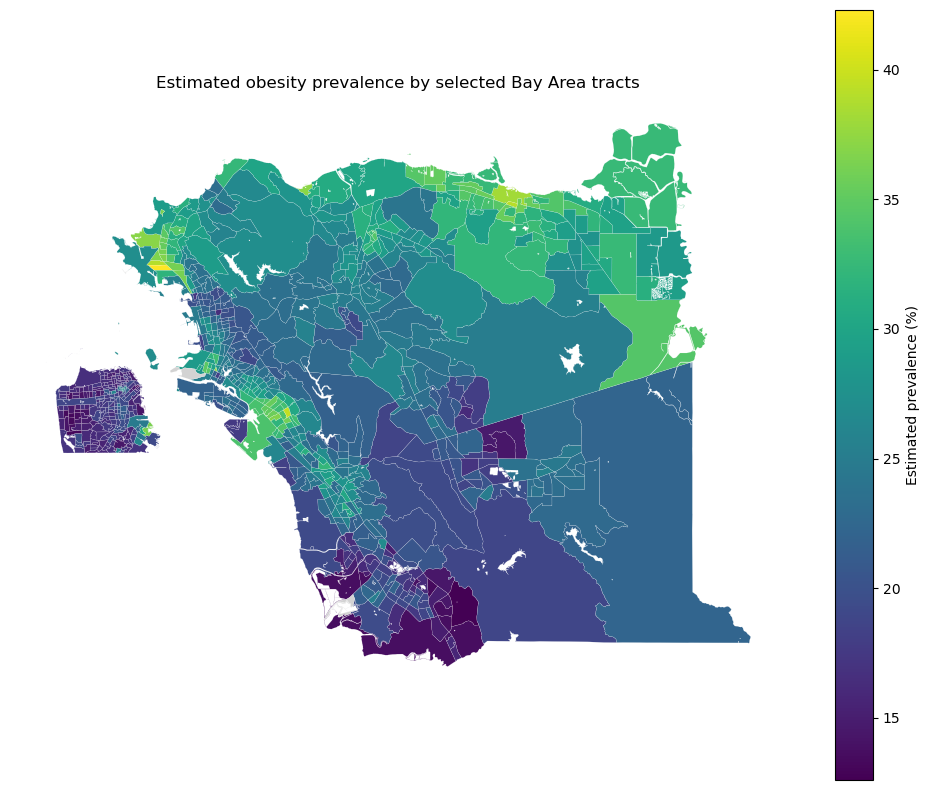

In [29]:
diseases = {"Obesity": "obesity"}

for title, column in diseases.items():
    fig, ax = plt.subplots(figsize=(10, 8))

    bay_health.plot(
        ax=ax,
        column=column,
        edgecolor="white",
        linewidth=0.1,
        legend=True,
        legend_kwds={"label": "Estimated prevalence (%)"},
        missing_kwds={"color": "lightgrey", "label": "No estimate"})

    ax.set_title(f"Estimated {title.lower()} prevalence by selected Bay Area tracts")
    ax.set_axis_off()
    plt.tight_layout()
    plt.savefig("outputs/obesity_map.png", dpi=200, bbox_inches="tight")
    plt.show()

In [30]:
!pip install session_info
import session_info
session_info.show()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [session_info]
